# Magic Pen (Air Gesture Drawing Model Training)

In this phase, we focus on training a robust machine learning model capable of recognizing specific hand gestures in real-time. By leveraging spatial data, the system translates physical hand movements into digital commands for an **Air Gesture Drawing** interface.

---

### System Overview
The pipeline follows a structured approach to transform raw video frames into actionable gesture classifications:

1.  **Hand Landmark Extraction:** Using **MediaPipe Hands**, we detect and track 21 3D hand landmarks.
2.  **Feature Engineering:** The $(x, y, z)$ coordinates of these landmarks are normalized to ensure the model remains scale and rotation invariant.
3.  **Gesture Classification:** A classifier categorizes the landmark patterns into four primary states:

| Gesture | Action | Description |
| :--- | :--- | :--- |
| **Draw** | ✍️ | Index finger extended; allows the user to write on the virtual canvas. |
| **Erase** | 🧼 | Multi-finger or fist gesture; clears specific areas or the entire screen. |
| **Scroll** | ↕️ | Specific hand movement to navigate through menus or pages. |
| **Cursor** | 🖱️ | Hand open; moves the pointer without active drawing. |

---

### 🎯 Objective
The goal of this notebook is to:
* **Preprocess** the collected landmark dataset.
* **Train** a classification model.
* **Evaluate** the model using a confusion matrix to ensure high precision across all gestures.
* **Export** the trained weights for integration into the real-time application.

#### **Data Exploration**

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [5]:
pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpy

In [2]:
df = pd.read_excel("final_gesture_data(2).xlsx")

df.head()

,label,Lx0,Ly0,Lz0,Lx1,Ly1,Lz1,Lx2,Ly2,Lz2,...,Rz17,Rx18,Ry18,Rz18,Rx19,Ry19,Rz19,Rx20,Ry20,Rz20
0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.024006,0.640282,0.638152,-0.043547,0.636939,0.677689,-0.036370,0.644005,0.714818,-0.025161
1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.017363,0.644825,0.643655,-0.034172,0.642093,0.680825,-0.028700,0.646941,0.717298,-0.019838
2,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.002029,0.611983,0.575341,-0.008682,0.607034,0.606629,-0.000598,0.612013,0.638193,0.008795
3,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.007133,0.551270,0.492378,0.004686,0.545436,0.519785,0.013260,0.552976,0.545225,0.022690
4,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.007748,0.548172,0.460406,-0.020481,0.540783,0.504239,-0.011554,0.552928,0.537528,0.000851


In [3]:
df.tail()

,label,Lx0,Ly0,Lz0,Lx1,Ly1,Lz1,Lx2,Ly2,Lz2,...,Rz17,Rx18,Ry18,Rz18,Rx19,Ry19,Rz19,Rx20,Ry20,Rz20
11195,6,0.288995,0.767966,4.287135e-07,0.342097,0.734379,-0.024341,0.382760,0.672709,-0.033789,...,-0.029339,0.712716,0.546194,-0.043773,0.720773,0.509211,-0.049394,0.726235,0.473791,-0.052878
11196,6,0.288774,0.769126,4.316670e-07,0.341045,0.736217,-0.024820,0.382618,0.674837,-0.034182,...,-0.028244,0.712457,0.545471,-0.041569,0.720198,0.509497,-0.046325,0.725249,0.475054,-0.049418
11197,6,0.288977,0.770658,4.370950e-07,0.340667,0.736280,-0.023632,0.381915,0.674275,-0.032190,...,-0.030308,0.713294,0.545872,-0.044576,0.721136,0.509273,-0.049748,0.726571,0.473975,-0.052933
11198,6,0.289415,0.770564,4.363370e-07,0.340811,0.736122,-0.024021,0.381802,0.674479,-0.032960,...,-0.030578,0.713281,0.546049,-0.044744,0.721431,0.509331,-0.049965,0.727200,0.473932,-0.053222
11199,6,0.287643,0.770659,4.303315e-07,0.341136,0.736336,-0.023583,0.382298,0.673392,-0.032108,...,-0.029672,0.713069,0.544187,-0.042855,0.720850,0.507616,-0.047633,0.725885,0.473022,-0.050720


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (11200, 127)


In [5]:
print("Data Duplication:", df.duplicated().sum())

Data Duplication: 0


In [6]:
print("\nClass Distribution:\n", df['label'].value_counts())
print("\nMissing Values:\n", df.isnull().sum())


Class Distribution:
 label
0    1600
1    1600
2    1600
3    1600
4    1600
5    1600
6    1600
Name: count, dtype: int64

Missing Values:
 label    0
Lx0      0
Ly0      0
Lz0      0
Lx1      0
        ..
Ry19     0
Rz19     0
Rx20     0
Ry20     0
Rz20     0
Length: 127, dtype: int64


#### **Feature Extraction**

In [7]:
X = df.drop("label", axis=1)
y = df["label"]

#### **Normalization**

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#### **Data Splitting**

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)


#### **Model Training**

In [10]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

In [11]:
rf = RandomForestClassifier(random_state=42)

grid = GridSearchCV(rf, param_grid, cv=3, n_jobs=-1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_

In [12]:
print("\nBest Parameters:", grid.best_params_)


Best Parameters: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}


#### **Model Evaluation**

In [13]:
y_pred = best_model.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred))

y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9973214285714286
Train Accuracy: 1.0
Test Accuracy: 0.9973214285714286

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.98      0.99       323
           1       1.00      1.00      1.00       326
           2       0.99      1.00      1.00       324
           3       1.00      1.00      1.00       338
           4       0.99      1.00      1.00       303
           5       1.00      1.00      1.00       322
           6       1.00      1.00      1.00       304

    accuracy                           1.00      2240
   macro avg       1.00      1.00      1.00      2240
weighted avg       1.00      1.00      1.00      2240



In [20]:
pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


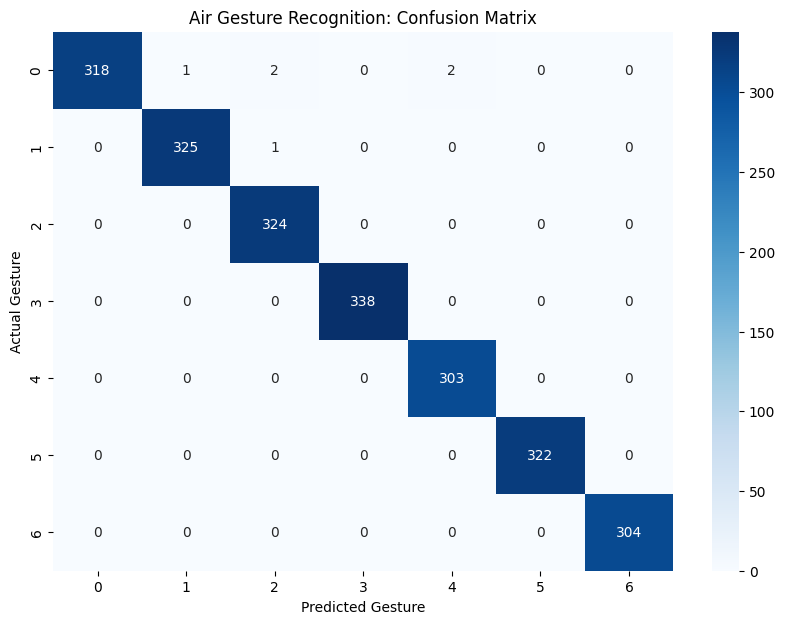

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Air Gesture Recognition: Confusion Matrix')
plt.xlabel('Predicted Gesture')
plt.ylabel('Actual Gesture')
plt.show()

In [15]:
import joblib

joblib.dump(best_model, "different_data_model3.pkl")
joblib.dump(scaler, "different_data_scaler3.pkl")

print("\nModel saved successfully!")


Model saved successfully!


#### **Testing Model**

In [ ]:
import cv2
import mediapipe as mp
import numpy as np
import joblib
from collections import deque

model = joblib.load("gesture_model1.pkl")
scaler = joblib.load("scaler1.pkl")

gestures = ["Draw", "Erase", "Scroll", "Cursor", "Color", "Screenshot", "Clear"]

mp_hands = mp.solutions.hands
hands = mp_hands.Hands(
    max_num_hands=2,
    min_detection_confidence=0.7,
    min_tracking_confidence=0.7
)
mp_draw = mp.solutions.drawing_utils

cap = cv2.VideoCapture(0)

gesture_buffer = deque(maxlen=10)

def extract_features_two_hands(results):
    left_hand = np.zeros(63)
    right_hand = np.zeros(63)

    if results.multi_hand_landmarks and results.multi_handedness:
        for hand_landmarks, handedness in zip(results.multi_hand_landmarks, results.multi_handedness):

            hand_features = []
            for lm in hand_landmarks.landmark:
                hand_features.extend([lm.x, lm.y, lm.z])

            if handedness.classification[0].label == "Left":
                left_hand = np.array(hand_features)
            else:
                right_hand = np.array(hand_features)

    features = np.concatenate([left_hand, right_hand])
    return features.reshape(1, -1)

while True:
    ret, frame = cap.read()
    if not ret:
        break

    frame = cv2.flip(frame, 1)

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    result = hands.process(rgb)

    gesture_name = "No Hand"

    if result.multi_hand_landmarks:

        for hand_landmarks in result.multi_hand_landmarks:
            mp_draw.draw_landmarks(frame, hand_landmarks, mp_hands.HAND_CONNECTIONS)

        try:

            features = extract_features_two_hands(result)

            features = scaler.transform(features)

            prediction = model.predict(features)[0]

            if int(prediction) < len(gestures):
                current_gesture = gestures[int(prediction)]
            else:
                current_gesture = "Unknown"

            gesture_buffer.append(current_gesture)
            gesture_name = max(set(gesture_buffer), key=gesture_buffer.count)

        except Exception as e:
            print("Error:", e)

    cv2.putText(frame, f'Gesture: {gesture_name}',
                (10, 50),
                cv2.FONT_HERSHEY_SIMPLEX,
                1,
                (0, 255, 0),
                2)

    cv2.imshow("Air Gesture Recognition", frame)

    if cv2.waitKey(1) & 0xFF == 27:
        break

cap.release()
cv2.destroyAllWindows()

c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\On

### **Training 2**

In [7]:
param_grid = {
    'n_estimators': [100, 200],
    'bootstrap' : [True, False],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'criterion': ['gini', 'entropy']
}

In [8]:
rf = RandomForestClassifier(random_state=42)

grid = GridSearchCV(rf, param_grid, cv=3, n_jobs=-1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_

In [9]:
print("\nBest Parameters:", grid.best_params_)


Best Parameters: {'bootstrap': False, 'criterion': 'gini', 'max_depth': 20, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}


In [10]:
y_pred = best_model.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred))

y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9978571428571429
Train Accuracy: 1.0
Test Accuracy: 0.9978571428571429

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      0.99       225
           1       1.00      1.00      1.00       206
           2       1.00      1.00      1.00       210
           3       1.00      1.00      1.00       185
           4       0.99      1.00      0.99       184
           5       1.00      1.00      1.00       206
           6       1.00      1.00      1.00       184

    accuracy                           1.00      1400
   macro avg       1.00      1.00      1.00      1400
weighted avg       1.00      1.00      1.00      1400



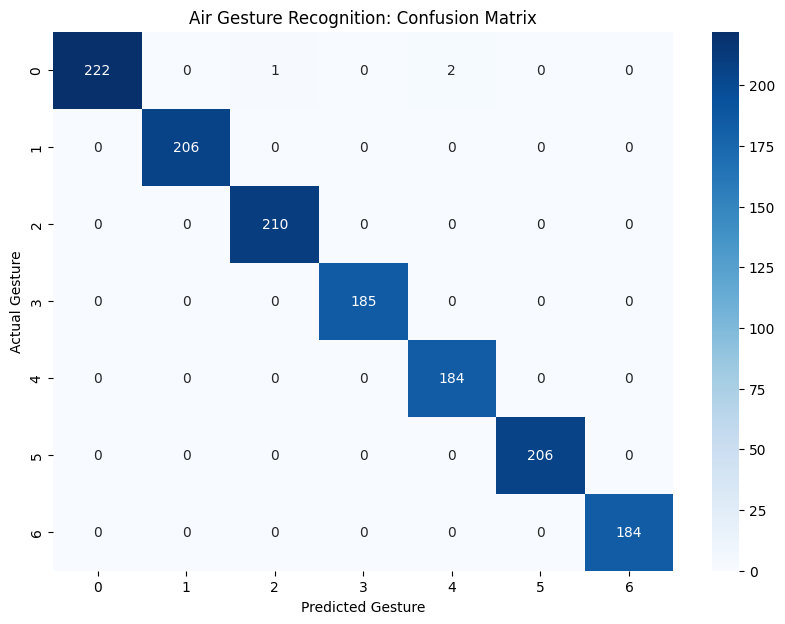

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Air Gesture Recognition: Confusion Matrix')
plt.xlabel('Predicted Gesture')
plt.ylabel('Actual Gesture')
plt.show()

In [12]:
import joblib

joblib.dump(best_model, "different_data_model2.pkl")
joblib.dump(scaler, "different_data_scaler2.pkl")

print("\nModel saved successfully!")


Model saved successfully!


In [ ]:
import cv2
import mediapipe as mp
import numpy as np
import joblib
from collections import deque

model = joblib.load("gesture_model.pkl")
scaler = joblib.load("scaler.pkl")

gestures = ["Draw", "Erase", "Scroll", "Cursor", "Color", "Screenshot", "Clear"]

mp_hands = mp.solutions.hands
hands = mp_hands.Hands(
    max_num_hands=2,
    min_detection_confidence=0.7,
    min_tracking_confidence=0.7
)
mp_draw = mp.solutions.drawing_utils

cap = cv2.VideoCapture(0)

gesture_buffer = deque(maxlen=10)

def extract_features_two_hands(results):
    left_hand = np.zeros(63)
    right_hand = np.zeros(63)

    if results.multi_hand_landmarks and results.multi_handedness:
        for hand_landmarks, handedness in zip(results.multi_hand_landmarks, results.multi_handedness):

            hand_features = []
            for lm in hand_landmarks.landmark:
                hand_features.extend([lm.x, lm.y, lm.z])

            if handedness.classification[0].label == "Left":
                left_hand = np.array(hand_features)
            else:
                right_hand = np.array(hand_features)

    features = np.concatenate([left_hand, right_hand])
    return features.reshape(1, -1)

while True:
    ret, frame = cap.read()
    if not ret:
        break

    frame = cv2.flip(frame, 1)

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    result = hands.process(rgb)

    gesture_name = "No Hand"

    if result.multi_hand_landmarks:

        for hand_landmarks in result.multi_hand_landmarks:
            mp_draw.draw_landmarks(frame, hand_landmarks, mp_hands.HAND_CONNECTIONS)

        try:

            features = extract_features_two_hands(result)

            features = scaler.transform(features)

            prediction = model.predict(features)[0]

            if int(prediction) < len(gestures):
                current_gesture = gestures[int(prediction)]
            else:
                current_gesture = "Unknown"

            gesture_buffer.append(current_gesture)
            gesture_name = max(set(gesture_buffer), key=gesture_buffer.count)

        except Exception as e:
            print("Error:", e)

    cv2.putText(frame, f'Gesture: {gesture_name}',
                (10, 50),
                cv2.FONT_HERSHEY_SIMPLEX,
                1,
                (0, 255, 0),
                2)

    cv2.imshow("Air Gesture Recognition", frame)

    if cv2.waitKey(1) & 0xFF == 27:
        break

cap.release()
cv2.destroyAllWindows()

c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\On